In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from PIL import Image

sys.path.append("..")
from src.class_map import PLANTDOC_TO_PLANTVILLAGE

DATA = Path("../data")
pv_classes = sorted(p.name for p in (DATA / "plantvillage/train").iterdir())
pd_classes = sorted(p.name for p in (DATA / "plantdoc/train").iterdir())

print("PlantVillage classes:", len(pv_classes))
print("PlantDoc classes:", len(pd_classes))

missing_in_map = [c for c in pd_classes if c not in PLANTDOC_TO_PLANTVILLAGE]
wrong_targets = [v for v in PLANTDOC_TO_PLANTVILLAGE.values() if v not in pv_classes]
print("PlantDoc classes missing from the map:", missing_in_map)
print("Map targets that don't exist in PlantVillage:", wrong_targets)

PlantVillage classes: 38
PlantDoc classes: 28
PlantDoc classes missing from the map: []
Map targets that don't exist in PlantVillage: []


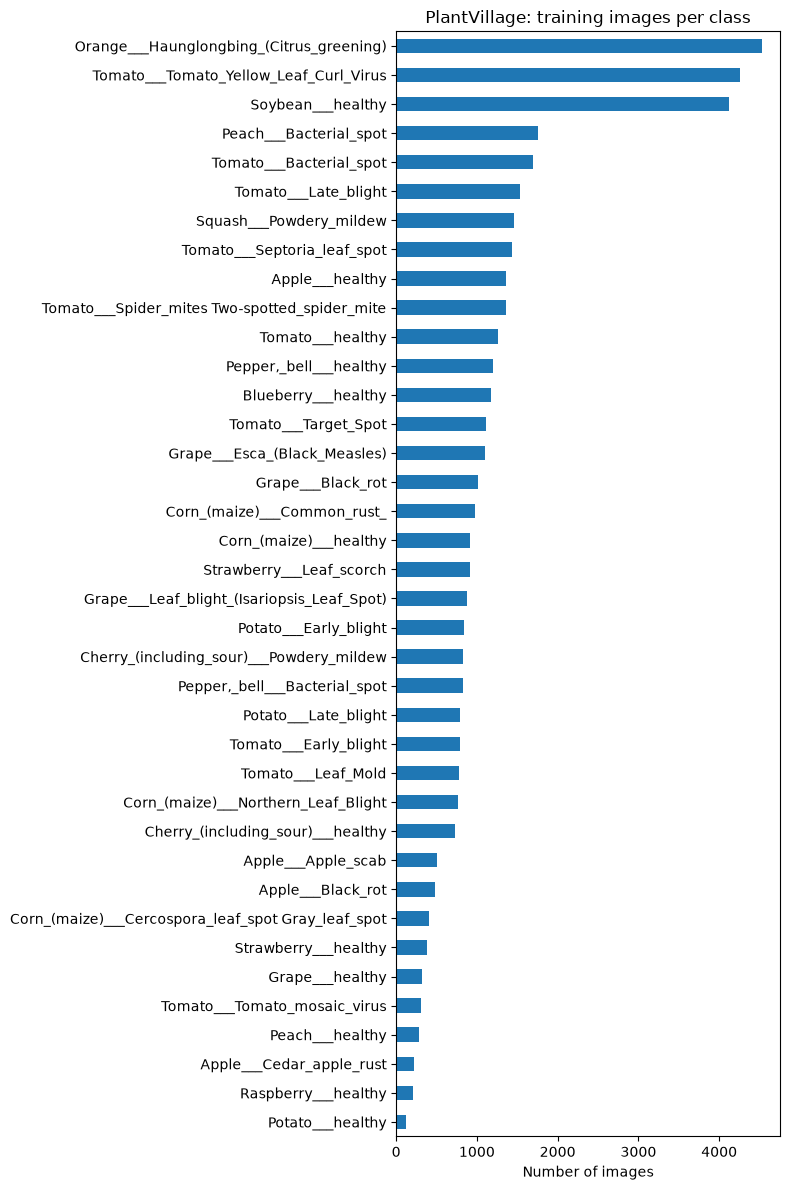

Most: Orange___Haunglongbing_(Citrus_greening) 4527
Fewest: Potato___healthy 120


In [2]:
counts = pd.Series({c: len(list((DATA / "plantvillage/train" / c).iterdir())) for c in pv_classes})

counts.sort_values().plot(kind="barh", figsize=(8, 12), title="PlantVillage: training images per class")
plt.xlabel("Number of images")
plt.tight_layout()
plt.show()

print("Most:", counts.idxmax(), counts.max())
print("Fewest:", counts.idxmin(), counts.min())

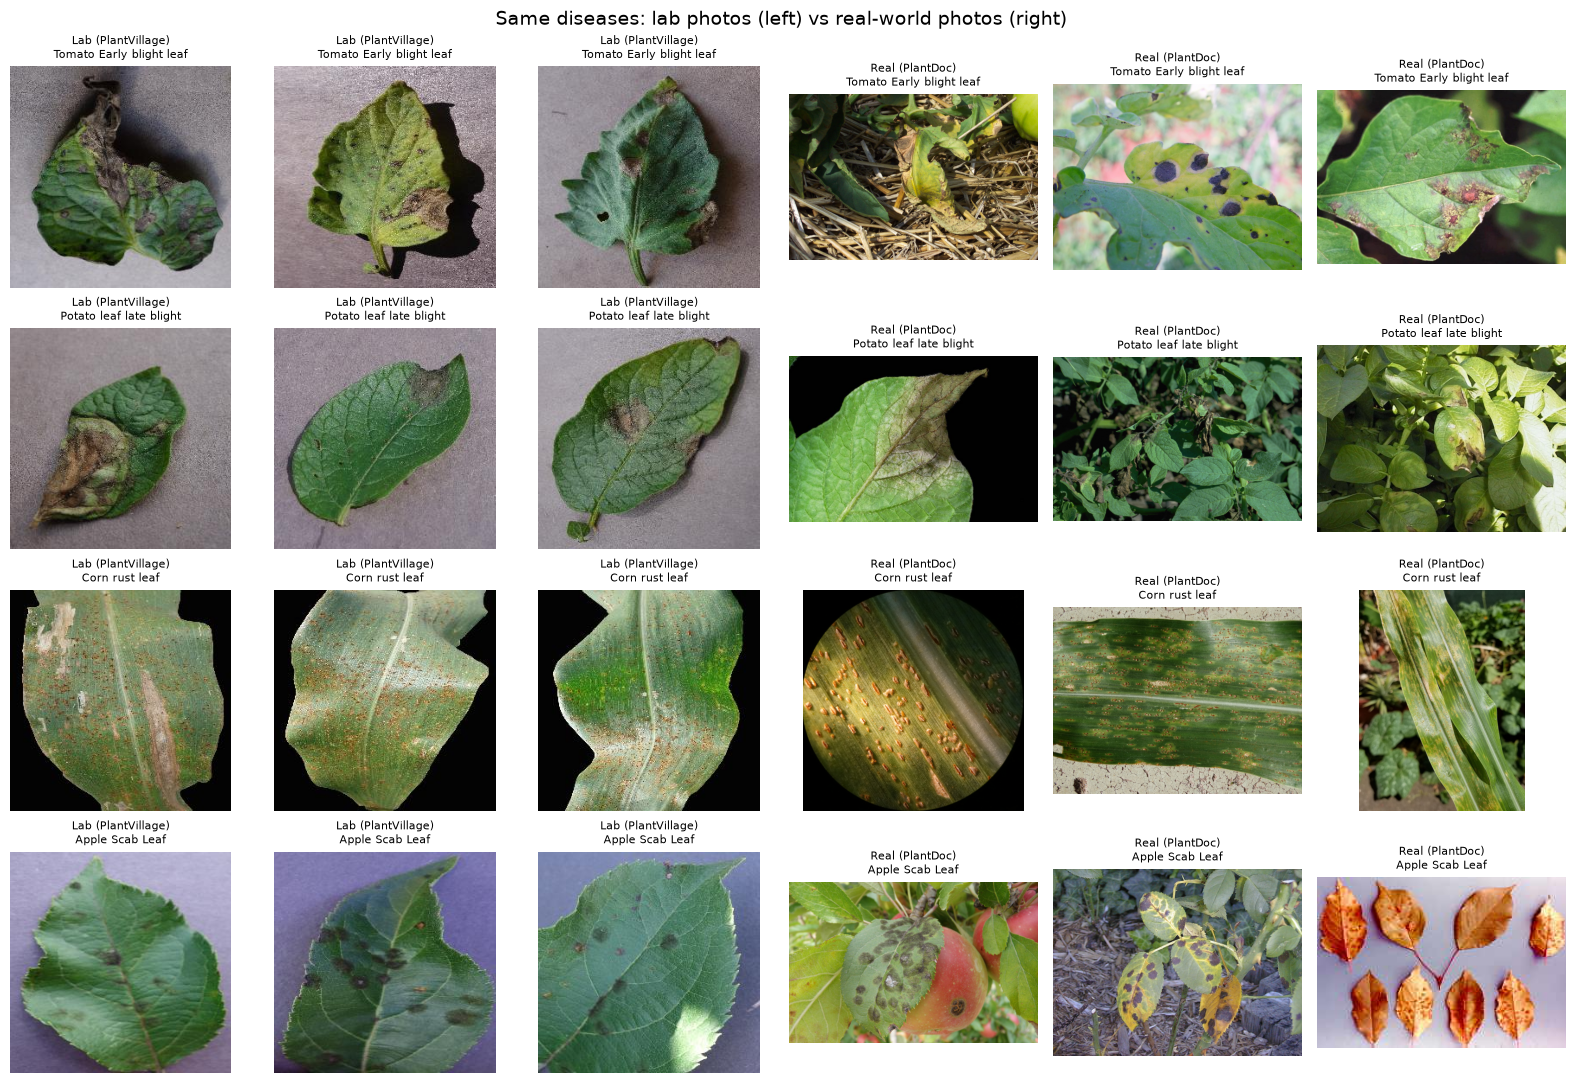

In [3]:
examples = ["Tomato Early blight leaf", "Potato leaf late blight", "Corn rust leaf", "Apple Scab Leaf"]

fig, axes = plt.subplots(len(examples), 6, figsize=(16, 11))
for row, pd_name in enumerate(examples):
    pv_name = PLANTDOC_TO_PLANTVILLAGE[pd_name]
    pv_imgs = sorted((DATA / "plantvillage/train" / pv_name).iterdir())[:3]
    pd_imgs = sorted((DATA / "plantdoc/train" / pd_name).iterdir())[:3]
    for col, img_path in enumerate(pv_imgs + pd_imgs):
        ax = axes[row, col]
        ax.imshow(Image.open(img_path).convert("RGB"))
        ax.axis("off")
        source = "Lab (PlantVillage)" if col < 3 else "Real (PlantDoc)"
        ax.set_title(f"{source}\n{pd_name}", fontsize=8)
plt.suptitle("Same diseases: lab photos (left) vs real-world photos (right)", fontsize=14)
plt.tight_layout()
plt.show()